# 3.1 $\quad$ Introducción a la optimización media-varianza

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

Cuando se trabaja con un conjunto de carteras aleatorias representadas como una nube de puntos en un espacio de rendimiento y riesgo, tal y como hemos hecho hasta ahora, se pueden observar diversas combinaciones de activos que ofrecen diferentes niveles de rendimiento y riesgo. La pregunta entonces es, **¿cuáles son las carteras eficientes?**. La optimización media-varianza busca identificar la cartera óptima dentro de esta nube de puntos, es decir, aquella cartera que proporciona el máximo rendimiento esperado para un nivel de riesgo dado o, alternativamente, el mínimo riesgo para un nivel de rendimiento objetivo.

Antes de entrar en detalle, veamos de nuevo una aproximación generando 2000 carteras aleatorias para 4 activos.

In [2]:
# Cargamos los datos.
filepath = "https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/refs/heads/Feb-2025/Tema_3_Markowitz/data/data.csv"
# filepath = "../data/data.csv"
data = pd.read_csv(filepath, index_col=0, parse_dates=True)

In [3]:
# Calculamos retornos de los activos.
retornos = np.log(data).diff().dropna()

In [4]:
# Número de activos.
num_act = retornos.shape[1]
# Número de carteras a simular.
num_carteras = 2000

In [5]:
# Generamos carteras aleatorias.
rng = np.random.default_rng(seed=42)
pesos = rng.random((num_carteras, num_act))
pesos /= np.sum(pesos, axis=1).reshape(-1, 1)
# Comprobamos que la suma de los pesos de cada cartera es 1.
np.sum(pesos, axis=1)

array([1., 1., 1., ..., 1., 1., 1.], shape=(2000,))

In [6]:
# Cálculo de retornos de las carteras.
ret_carteras = retornos @ pesos.T  # (2061, 2000)
# Cálculo de retornos y volatilidades anualizadas.
volatilidades = np.std(ret_carteras, axis=0) * np.sqrt(252)
rentabilidades = np.mean(ret_carteras, axis=0) * 252

print(f"volatilidades: {volatilidades.shape}")
print(f"rentabilidades: {rentabilidades.shape}")

volatilidades: (2000,)
rentabilidades: (2000,)


Dado un **riesgo máximo** asumible de 0.13, ¿cuál es la cartera eficiente? El código siguiente genera una figura donde poder discutir qué decisión tomamos.

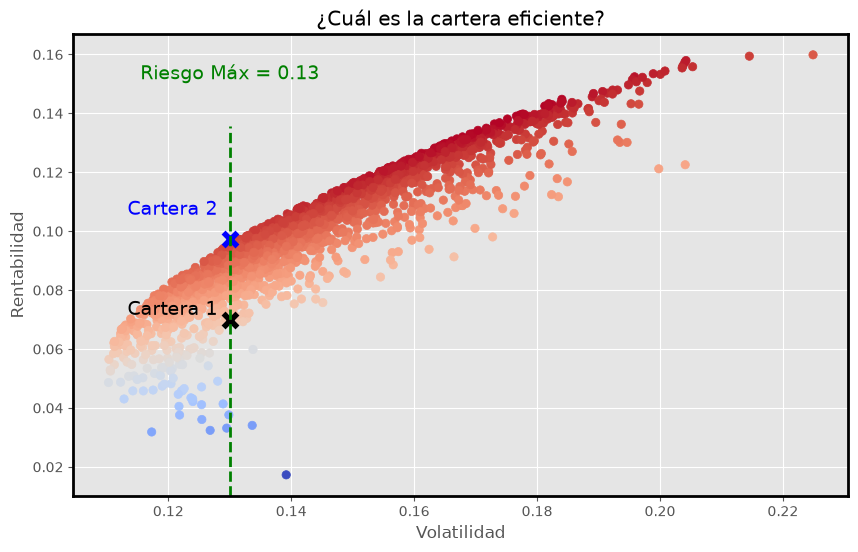

In [7]:
# grafico

plt.figure(figsize=(10, 6))
plt.scatter(x=volatilidades, y=rentabilidades, c=rentabilidades / volatilidades, marker="o", cmap="coolwarm")
plt.xlabel("Volatilidad")
plt.ylabel("Rentabilidad")
plt.title("¿Cuál es la cartera eficiente?")


# Añadir un segmento vertical
plt.axvline(x=0.13, ymin=0, ymax=0.8, color="green", linestyle="--", linewidth=2)

# Añadir etiqueta al segmento vertical
plt.text(0.13, 0.15, "Riesgo Máx = 0.13", fontsize=14, verticalalignment="bottom", horizontalalignment="center", color="green")


# Añadir puntos específicos
plt.scatter(0.13, 0.07, color="black", marker="x", s=100, linewidths=4)  # Punto para la cartera 1
plt.scatter(0.13, 0.0975, color="blue", marker="x", s=100, linewidths=4)  # Punto para la cartera 2

# Añadir etiquetas para los puntos
plt.text(0.128, 0.07, "Cartera 1", fontsize=14, verticalalignment="bottom", horizontalalignment="right", color="black")
plt.text(0.128, 0.104, "Cartera 2", fontsize=14, verticalalignment="bottom", horizontalalignment="right", color="blue")

# Configurar el borde de la figura
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(2)


plt.show()

También podemos hacerlo partiendo de un rendimiento mínimo. Dada una **rentabilidad mínima exigida** de un 0.08, ¿cuál es la cartera eficiente? Veamos la siguiente figura para discutirlo.

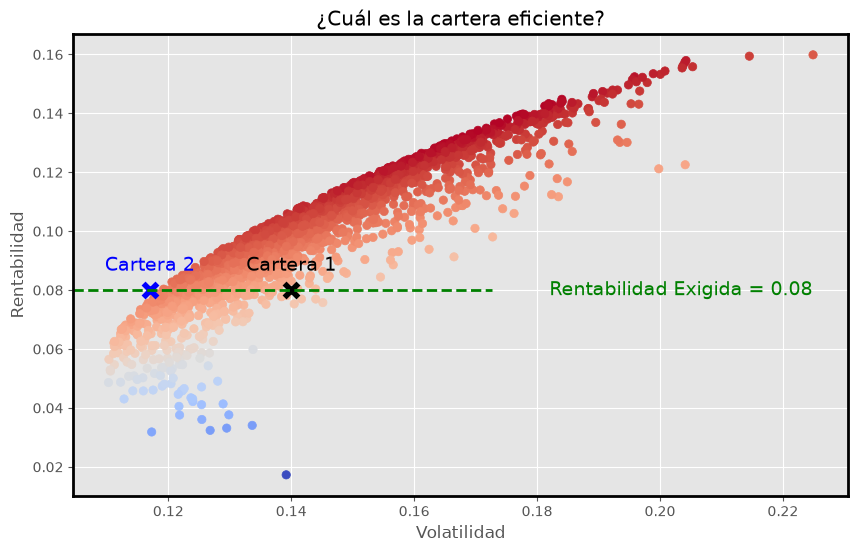

In [8]:
# grafico

plt.figure(figsize=(10, 6))
plt.scatter(x=volatilidades, y=rentabilidades, c=rentabilidades / volatilidades, marker="o", cmap="coolwarm")
plt.xlabel("Volatilidad")
plt.ylabel("Rentabilidad")
plt.title("¿Cuál es la cartera eficiente?")
# plt.colorbar(label='Sharpe ratio')

# Añadir un segmento vertical
plt.axhline(xmin=0, xmax=0.54, y=0.08, color="green", linestyle="--", linewidth=2)

# Añadir etiqueta al segmento vertical
plt.text(0.182, 0.08, "Rentabilidad Exigida = 0.08", fontsize=14, verticalalignment="center", horizontalalignment="left", color="green")


# Añadir puntos específicos
plt.scatter(0.14, 0.08, color="black", marker="x", s=100, linewidths=4)  # Punto para la cartera 1
plt.scatter(0.117, 0.08, color="blue", marker="x", s=100, linewidths=4)  # Punto para la cartera 2

# Añadir etiquetas para los puntos
plt.text(0.14, 0.085, "Cartera 1", fontsize=14, verticalalignment="bottom", horizontalalignment="center", color="black")
plt.text(0.117, 0.085, "Cartera 2", fontsize=14, verticalalignment="bottom", horizontalalignment="center", color="blue")

# Configurar el borde de la figura
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(2)


plt.show()

La optimización media-varianza de carteras (MVO por sus siglas en inglés) es una herramienta fundamental en el mundo de las finanzas que busca maximizar el rendimiento esperado de una cartera de activos mientras se minimiza el riesgo asociado. Este enfoque se basa en la teoría moderna de carteras desarrollada por Harry Markowitz en la década de 1950, que establece que los inversores pueden construir carteras óptimas que ofrecen el mejor equilibrio posible entre rendimiento y riesgo. 

En resumen, la optimización media-varianza es una herramienta poderosa que proporciona un marco sistemático para la construcción y gestión de carteras de inversión, ayudando a los inversores a alcanzar sus metas financieras de manera más efectiva y eficiente.

# 1. Modelo de Markowitz
Markowitz propone maximizar la siguiente función de utilidad:

$$\underset{w}{\max} f(w)=\underbrace{w^T\mu}_{\text{rentabilidad}} - \lambda \underbrace{w^T\Sigma w}_{\text{riesgo}} \tag{1}$$

donde:

- $\mu$ es la matriz de los retornos esperados

- $ \lambda$ es el coeficiente de aversión al riesgo (o tolerancia al riesgo)

- $ \Sigma$ es la matriz de varianzas-covarianzas


Dos inversores pueden tener distinta tolerancia al riesgo y por lo tanto tener distintas carteras eficientes.




SI calculamos la primera derivada e igualamos a cero:

$$\frac{\partial f(w)}{\partial w}=\mu-2 \lambda \Sigma w=0$$
<br>

Dado que la función $f(w)$ es cóncava, la condición de primer orden define un único máximo. Por tanto:

$$w=\frac{1}{2\lambda}\Sigma^{-1} \tag{2}\mu$$

**NOTA** más adelante veremos como el componente $\Sigma^{-1}$ (inversa de la matriz de covarianzas) supone un reto a la hora de optimizar carteras.

## 2. MEDIA-VARIANZA: Frontera Eficiente

Con todo esto, podemos plantear el problema de calcular la frontera eficiente como un **problema de optimización**.

$\qquad \underset{w}{\max} f(w)=w^T\mu-\lambda w^T\Sigma w$

$\qquad s.t. \qquad w^T\mathbf I=1$



En el siguiente notebook vamos a resolver, de manera analítica, este problema de optimización [3.2 optimización analítica](optimizacion-analitica.ipynb)